Name: Jess Choi  
Github Username: yulimjchoi  
USC ID: 9452440573 

## 1. Decision Trees as Interpretable Models

Import packages

In [127]:
import pandas as pd

### (a) Obtain Data

Get the Accute Inamations Data Set

In [128]:
columns = ["temperature", "nausea", "lumbar-pain", "urine-pushing", "micturition-pains", "burning-urethra", "bladder-inflammation", "nephritis"]
df1 = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, names=columns, encoding="utf-16", decimal=",")
df1.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra,bladder-inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [129]:
df1.dtypes

temperature             float64
nausea                      str
lumbar-pain                 str
urine-pushing               str
micturition-pains           str
burning-urethra             str
bladder-inflammation        str
nephritis                   str
dtype: object

In [130]:
df1.isna().sum()

temperature             0
nausea                  0
lumbar-pain             0
urine-pushing           0
micturition-pains       0
burning-urethra         0
bladder-inflammation    0
nephritis               0
dtype: int64

In [131]:
binary_columns = columns[1:]

for column in binary_columns:
    df1[column] = df1[column].map({"yes": 1, "no": 0})

df1.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra,bladder-inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [132]:
feature_1 = columns[:6]
target_1 = columns[6:]

X_df1 = df1[feature_1]
y_df1 = df1[target_1]

In [133]:
y_joint = (y_df1["bladder-inflammation"].astype(str)
           + "_"
           + y_df1["nephritis"].astype(str)
)

joint_labels = {
    "0_0": "neither",
    "0_1": "nephritis only",
    "1_0": "bladder-inflammation only",
    "1_1": "both"
}

y_joint.value_counts().sort_index()

0_0    30
0_1    31
1_0    40
1_1    19
Name: count, dtype: int64

### (b) Build a decision tree

In [134]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(criterion="gini", random_state=42)
tree.fit(X_df1, y_joint)

print("training accuracy:", tree.score(X_df1, y_joint))
print("tree depth:", tree.get_depth())
print("number of leaves:", tree.get_n_leaves())

training accuracy: 1.0
tree depth: 4
number of leaves: 6


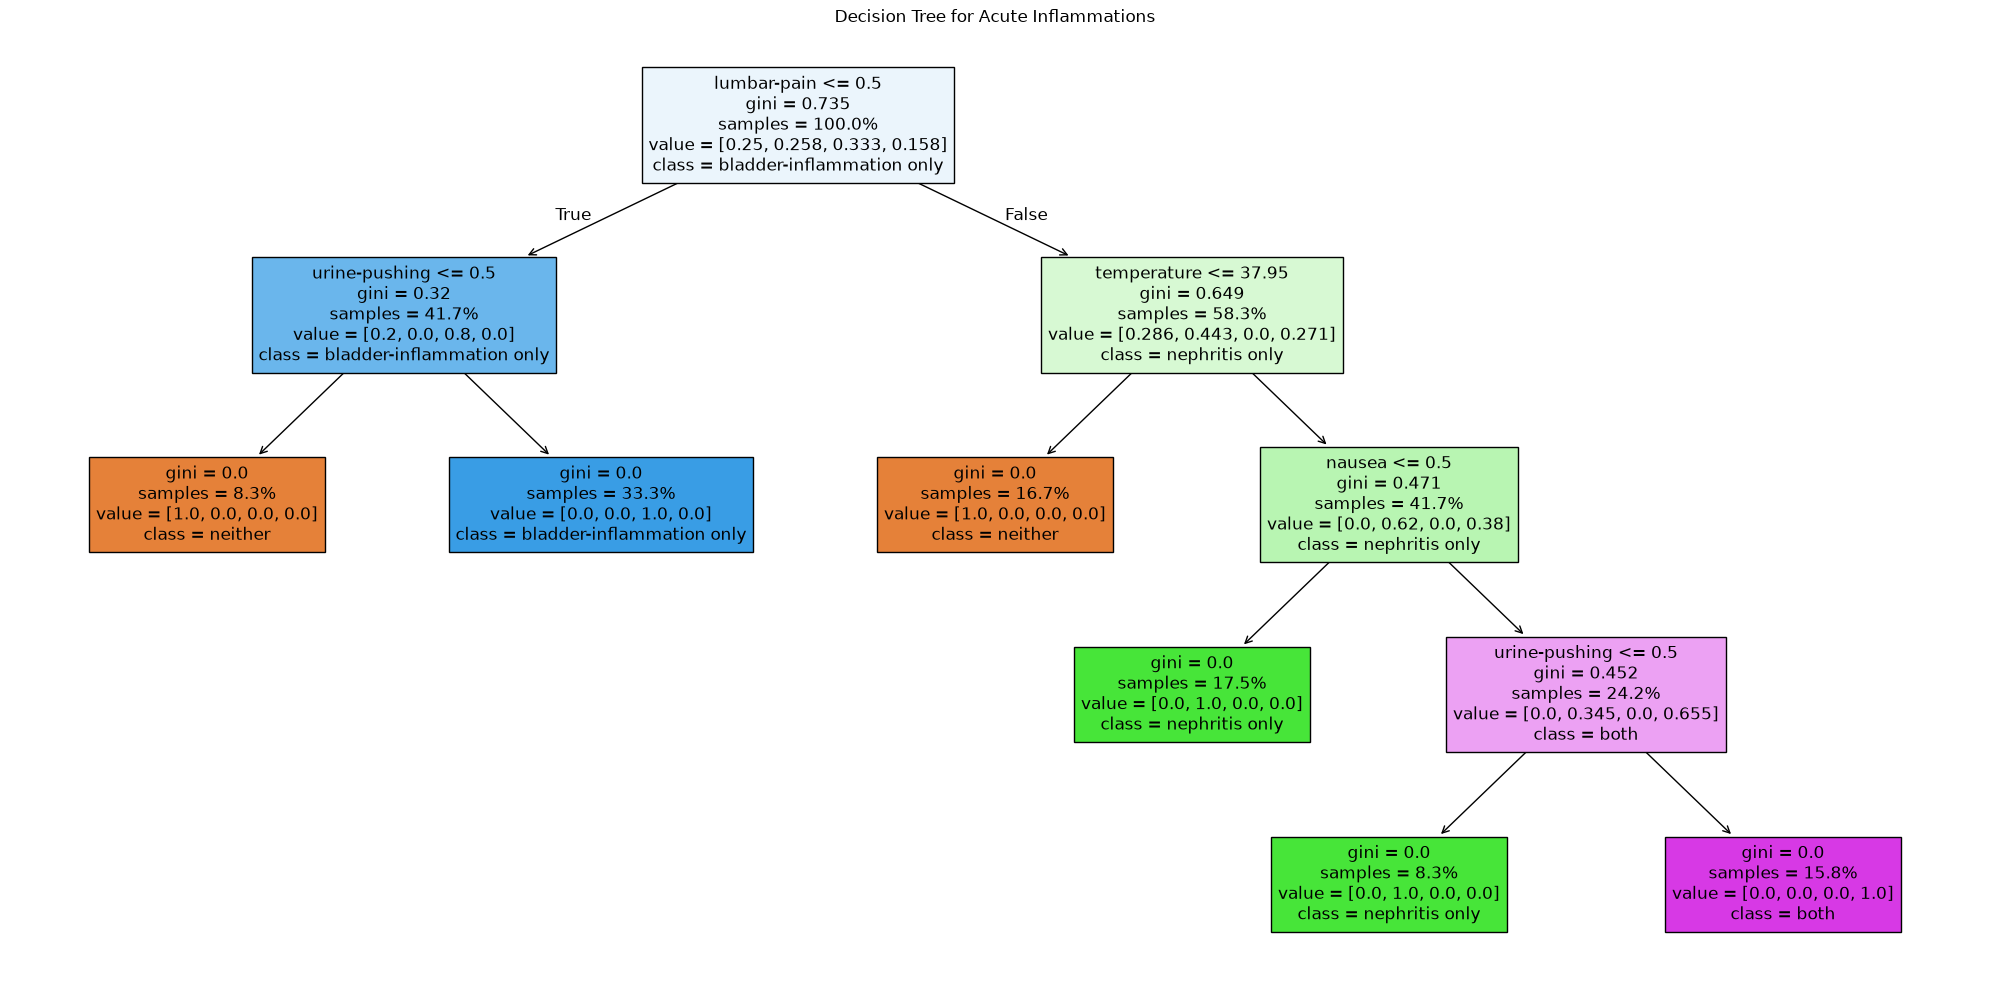

In [135]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

class_names_1 = [joint_labels[label] 
                 for label in tree.classes_
]

plt.figure(figsize=(20,10))

plot_tree(tree, feature_names=feature_1, class_names=class_names_1, filled=True, impurity=True, proportion=True)

plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [136]:
def tree_to_pseudo(tree, feature_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [
        feature_names[i]
        for i in tree.tree_.feature
    ]
    value = tree.tree_.value

    def recurse(left, right, threshold, features, node, depth=0):
        indent = "  " * depth

        if threshold[node] != -2:
            print(
                indent
                + "if ("
                + features[node]
                + " <= "
                + str(round(threshold[node], 2))
                + ") {"
            )

            if left[node] != -1:
                recurse(left, right, threshold, features, left[node], depth + 1)

            print(indent + "} else {")

            if right[node] != -1:
                recurse(left, right, threshold, features, right[node], depth + 1)

            print(indent + "}")

        else:
            print(
                indent
                + "return "
                + str(value[node])
            )

    recurse(left, right, threshold, features, 0)

In [137]:
print("class order:", tree.classes_)
tree_to_pseudo(tree, feature_1)

class order: ['0_0' '0_1' '1_0' '1_1']
if (lumbar-pain <= 0.5) {
  if (urine-pushing <= 0.5) {
    return [[1. 0. 0. 0.]]
  } else {
    return [[0. 0. 1. 0.]]
  }
} else {
  if (temperature <= 37.95) {
    return [[1. 0. 0. 0.]]
  } else {
    if (nausea <= 0.5) {
      return [[0. 1. 0. 0.]]
    } else {
      if (urine-pushing <= 0.5) {
        return [[0. 1. 0. 0.]]
      } else {
        return [[0. 0. 0. 1.]]
      }
    }
  }
}


### (d) Pruning

In [138]:
path = tree.cost_complexity_pruning_path(X_df1, y_joint)

ccp_alphas = path.ccp_alphas

ccp_alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

In [139]:
trees = []

for alpha in ccp_alphas:
    pruned_tree = DecisionTreeClassifier(criterion="gini", random_state=42, ccp_alpha=alpha)

    pruned_tree.fit(X_df1, y_joint)
    trees.append(pruned_tree)

In [140]:
pruning_results = pd.DataFrame({
    "ccp_alpha": ccp_alphas,
    "training_accuracy": [model.score(X_df1, y_joint) for model in trees],
    "depth": [model.get_depth() for model in trees],
    "leaves": [model.get_n_leaves() for model in trees]
})

pruning_results

,ccp_alpha,training_accuracy,depth,leaves
0,0.000000,1.000000,4,6
1,0.098167,0.841667,2,4
2,0.133333,0.758333,2,3
3,0.182000,0.591667,1,2
4,0.222917,0.333333,0,1


In [141]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_accuracy = []

for model in trees:
    scores = cross_val_score(model, X_df1, y_joint, cv=cv, scoring="accuracy")

    cv_accuracy.append(scores.mean())

pruning_results["cv_accuracy"] = cv_accuracy

pruning_results

,ccp_alpha,training_accuracy,depth,leaves,cv_accuracy
0,0.000000,1.000000,4,6,0.991667
1,0.098167,0.841667,2,4,0.858333
2,0.133333,0.758333,2,3,0.758333
3,0.182000,0.591667,1,2,0.666667
4,0.222917,0.333333,0,1,0.483333


In [142]:
pruned_candidates = pruning_results[pruning_results["ccp_alpha"] > 0]
selected_index = (pruned_candidates["cv_accuracy"].idxmax())
selected_alpha = pruning_results.loc[selected_index, "ccp_alpha"]

selected_alpha

np.float64(0.09816666666666667)

Although the unpruned tree with ccp alpha equal to zero achieved the highest cross-validation accuracy, it did not remove any branches. Therefore, among the models with positive ccp alpha values, I selected the model with the highest cross-validation accuracy. The selected ccp alpha was approximately 0.098167. It reduced the tree depth from 4 to 2 and the number of leaves from 6 to 4. Its cross-validation accuracy was 0.8583, compared with 0.9917 for the unpruned tree. Therefore, the selected tree sacrifices some predictive accuracy in exchange for fewer and simpler decision rules.

In [143]:
minimal_tree = DecisionTreeClassifier(criterion="gini", random_state=42, ccp_alpha=selected_alpha)

minimal_tree.fit(X_df1, y_joint)

print("selected alpha:", selected_alpha)
print("training accuracy:", minimal_tree.score(X_df1, y_joint))
print("tree depth:", minimal_tree.get_depth())
print("number of leaves:", minimal_tree.get_n_leaves())

selected alpha: 0.09816666666666667
training accuracy: 0.8416666666666667
tree depth: 2
number of leaves: 4


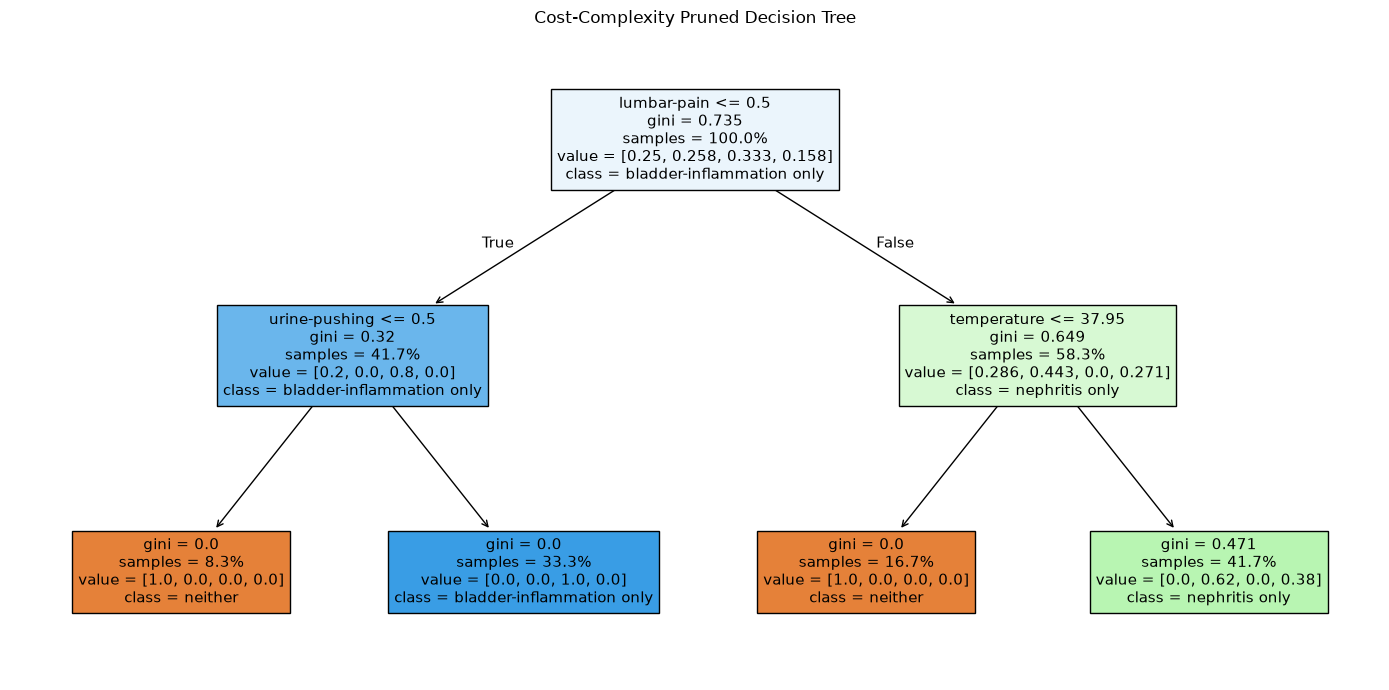

In [144]:
minimal_class_names = [joint_labels[label] for label in minimal_tree.classes_]

plt.figure(figsize=(14, 7))

plot_tree(
    minimal_tree,
    feature_names=feature_1,
    class_names=minimal_class_names,
    filled=True,
    impurity=True,
    proportion=True
)

plt.title("Cost-Complexity Pruned Decision Tree")
plt.tight_layout()
plt.show()

In [145]:
print("class order:", minimal_tree.classes_)
tree_to_pseudo(minimal_tree, feature_1)

class order: ['0_0' '0_1' '1_0' '1_1']
if (lumbar-pain <= 0.5) {
  if (urine-pushing <= 0.5) {
    return [[1. 0. 0. 0.]]
  } else {
    return [[0. 0. 1. 0.]]
  }
} else {
  if (temperature <= 37.95) {
    return [[1. 0. 0. 0.]]
  } else {
    return [[0.   0.62 0.   0.38]]
  }
}


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [146]:
# Check columns

with open("../data/communities.names") as file:
    names_lines = file.readlines()

for line_number, line in enumerate(
    names_lines,
    start=1
):
    print(line_number, line.rstrip())

1 Title: Communities and Crime
2 
3 Abstract: Communities within the United States. The data combines socio-economic data
4 from the 1990 US Census, law enforcement data from the 1990 US LEMAS survey, and crime
5 data from the 1995 FBI UCR.
6 
7 -----------------------------------------------------------------------------------------
8 
9 Data Set Characteristics:  Multivariate
10 Attribute Characteristics: Real
11 Associated Tasks: Regression
12 Number of Instances: 1994
13 Number of Attributes: 128
14 Missing Values? Yes
15 Area: Social
16 Date Donated: 2009-07-13
17 
18 -----------------------------------------------------------------------------------------
19 
20 Source:
21 
22 Creator: Michael Redmond (redmond 'at' lasalle.edu); Computer Science; La Salle
23 University; Philadelphia, PA, 19141, USA
24 -- culled from 1990 US Census, 1995 US FBI Uniform Crime Report, 1990 US Law
25 Enforcement Management and Administrative Statistics Survey, available from ICPSR at U
26 of Michigan

In [147]:
for line in names_lines:
    if (
        "not predictive" in line.lower()
        or "not counted as predictive" in line.lower()
        or "goal attribute" in line.lower()
    ):
        print(line.strip())

-- state: US state (by number) - not counted as predictive above, but if considered, should be consided nominal (nominal)
-- county: numeric code for county - not predictive, and many missing values (numeric)
-- community: numeric code for community - not predictive and many missing values (numeric)
-- communityname: community name - not predictive - for information only (string)
-- fold: fold number for non-random 10 fold cross validation, potentially useful for debugging, paired tests - not predictive (numeric)
-- ViolentCrimesPerPop: total number of violent crimes per 100K popuation (numeric - decimal) GOAL attribute (to be predicted)


In [148]:
# Get columns name

attribute_names = []

for line in names_lines:
    if line.strip().lower().startswith("@attribute"):
        attribute_names.append(line.split()[1])

len(attribute_names)

128

In [149]:
# Load the data

df2 = pd.read_csv("../data/communities.data", header=None, names=attribute_names, na_values="?")

df2.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [150]:
df2.shape

(1994, 128)

In [151]:
# Split the data: train/test set

train_df2 = df2.iloc[:1495].copy()
test_df2 = df2.iloc[1495:].copy()

print("training set:", train_df2.shape)
print("test set:", test_df2.shape)

training set: (1495, 128)
test set: (499, 128)


### (b) Missing values

In [152]:
# non-predictive features and target

non_predictive = ["state", "county", "community", "communityname", "fold"]

target_2 = "ViolentCrimesPerPop"

In [153]:
X_train = train_df2.drop(columns=non_predictive + [target_2])

y_train = train_df2[target_2]

In [154]:
X_test = test_df2.drop(columns=non_predictive + [target_2])

y_test = test_df2[target_2]

In [155]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1495, 122)
y_train: (1495,)
X_test: (499, 122)
y_test: (499,)


In [156]:
# Check missing values

missing_values = X_train.isna().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values

PctPolicBlack           1256
PctPolicHisp            1256
LemasGangUnitDeploy     1256
LemasPctPolicOnPatr     1256
PolicOperBudg           1256
PolicCars               1256
PolicAveOTWorked        1256
NumKindsDrugsSeiz       1256
OfficAssgnDrugUnits     1256
PctPolicMinor           1256
PctPolicAsian           1256
PolicBudgPerPop         1256
LemasSwornFT            1256
PctPolicWhite           1256
RacialMatchCommPol      1256
PolicPerPop             1256
PolicReqPerOffic        1256
LemasTotReqPerPop       1256
LemasTotalReq           1256
LemasSwFTFieldPerPop    1256
LemasSwFTFieldOps       1256
LemasSwFTPerPop         1256
OtherPerCap                1
dtype: int64

In [157]:
print("missing values in y_train:", y_train.isna().sum())
print("missing values in y_test:", y_test.isna().sum())

missing values in y_train: 0
missing values in y_test: 0


In [161]:
# Data imputation

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [162]:
print(
    "missing values in X_train:",
    X_train_imputed.isna().sum().sum()
)

print(
    "missing values in X_test:",
    X_test_imputed.isna().sum().sum()
)

missing values in X_train: 0
missing values in X_test: 0


### (c) Plot a correlation matrix

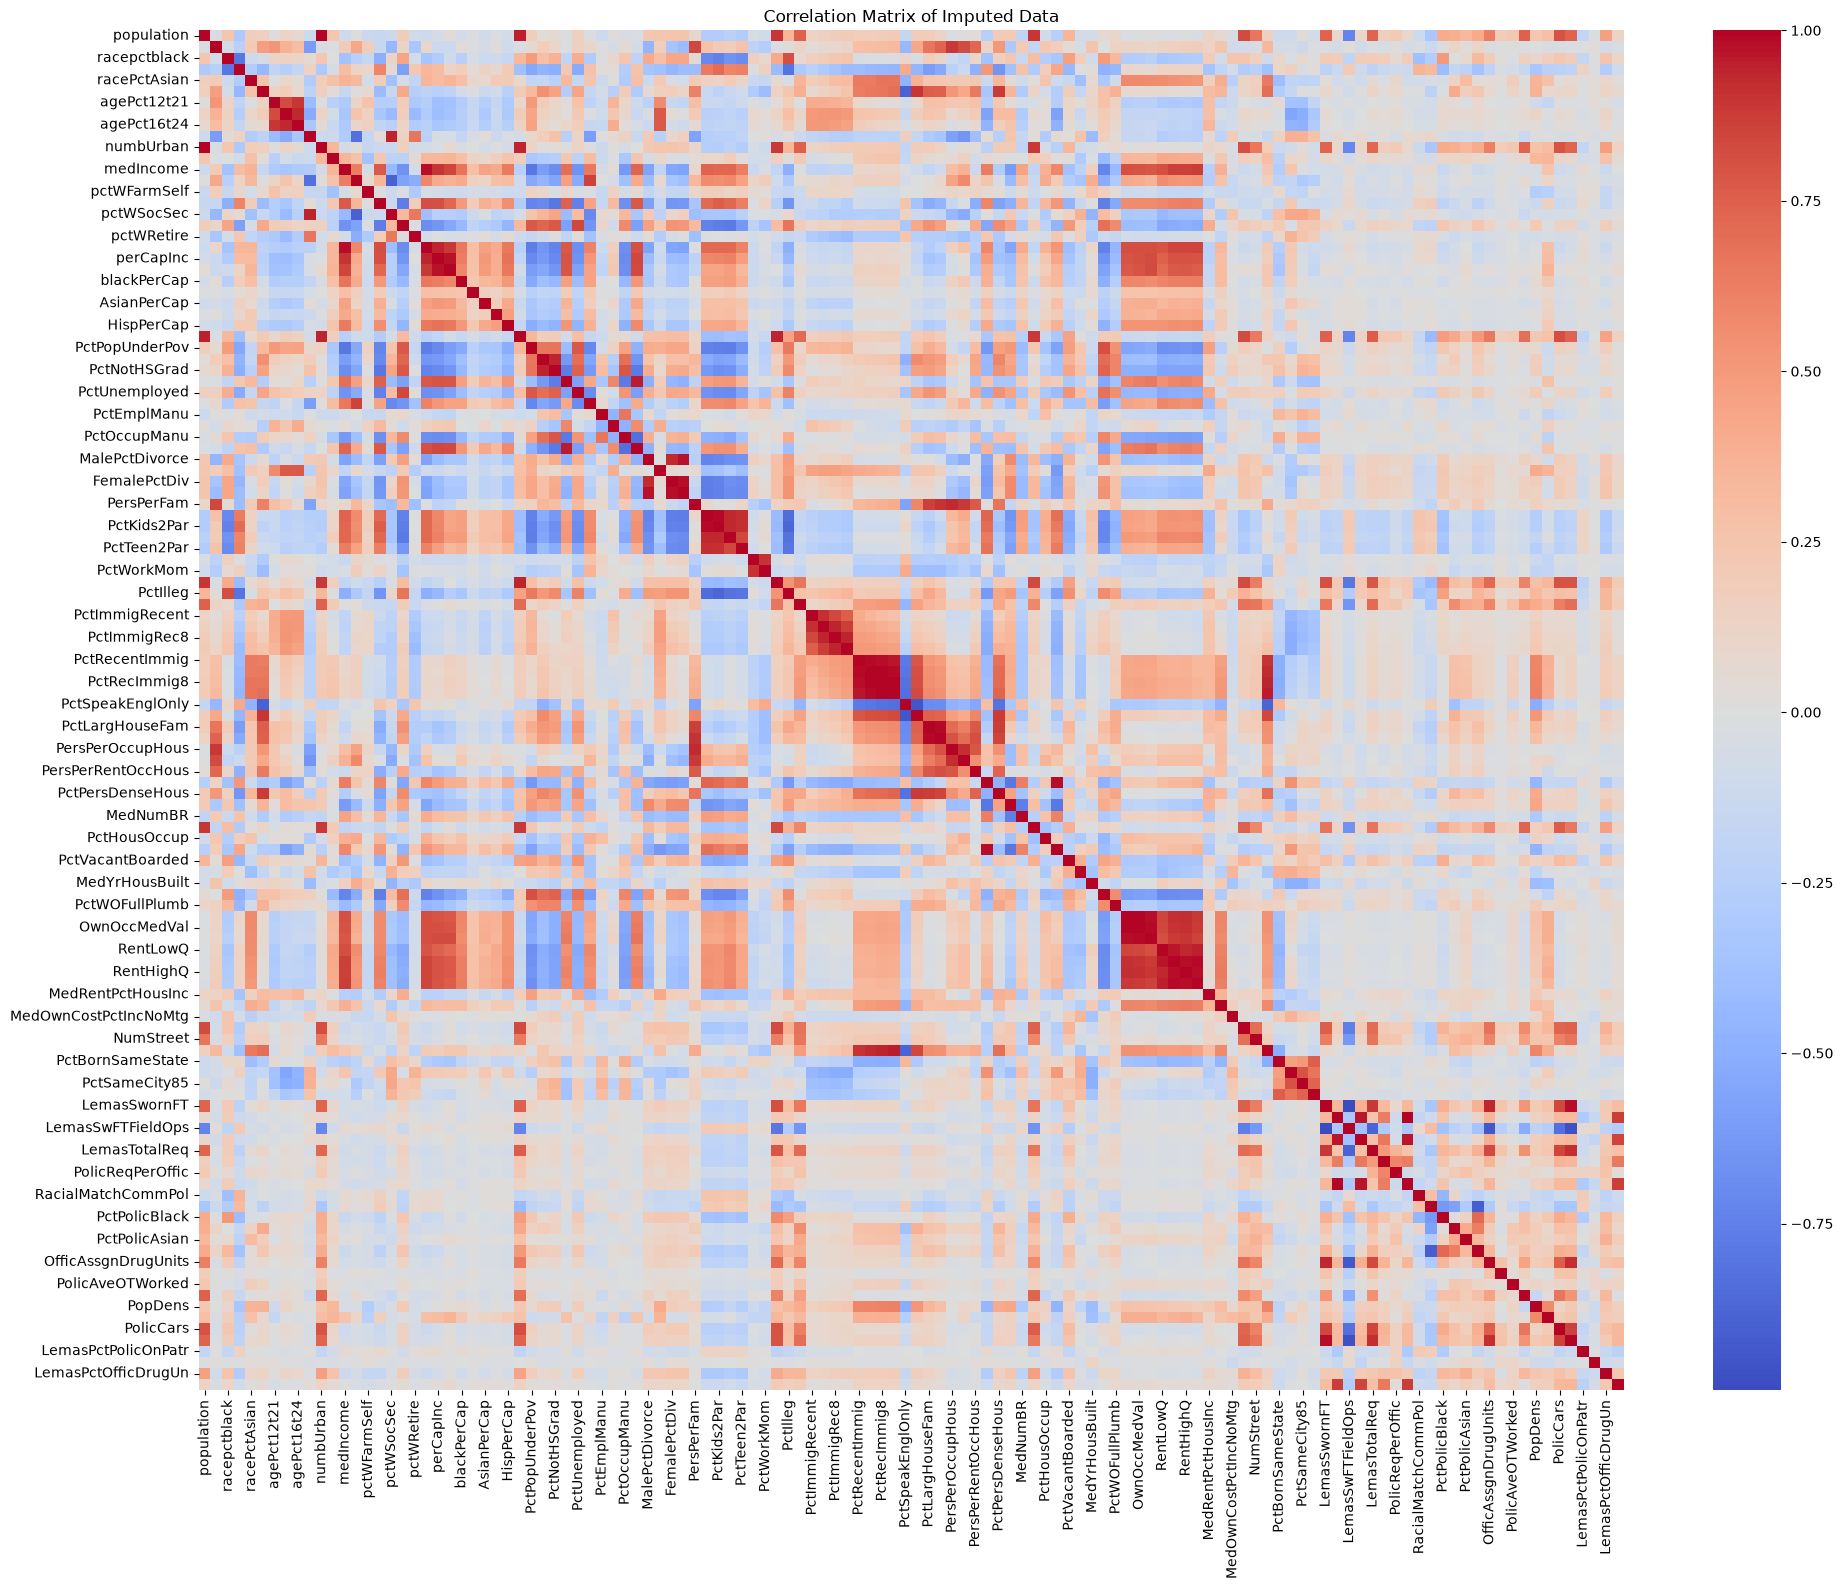

In [165]:
import seaborn as sns

corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)

plt.title("Correlation Matrix of Imputed Data")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [168]:
feature_mean = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)

cv = (feature_std / feature_mean.replace(0, pd.NA))

cv_results = pd.DataFrame({
    "mean": feature_mean,
    "std": feature_std,
    "cv": cv
}).sort_values(
    "cv",
    ascending=False
)

cv_results

,mean,std,cv
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Scatter plots and box plots for highest CV features

In [170]:
import numpy as np
number_of_features = int(
    np.floor(np.sqrt(128))
)

top_cv_features = (
    cv_results
    .head(number_of_features)
    .index
    .tolist()
)

print("number of features:", number_of_features)
print("features with the highest CV:")

for feature in top_cv_features:
    print(feature)

number of features: 11
features with the highest CV:
PctPolicAsian
NumStreet
NumInShelters
NumIlleg
NumImmig
LemasPctOfficDrugUn
NumUnderPov
LemasSwornFT
population
numbUrban
HousVacant


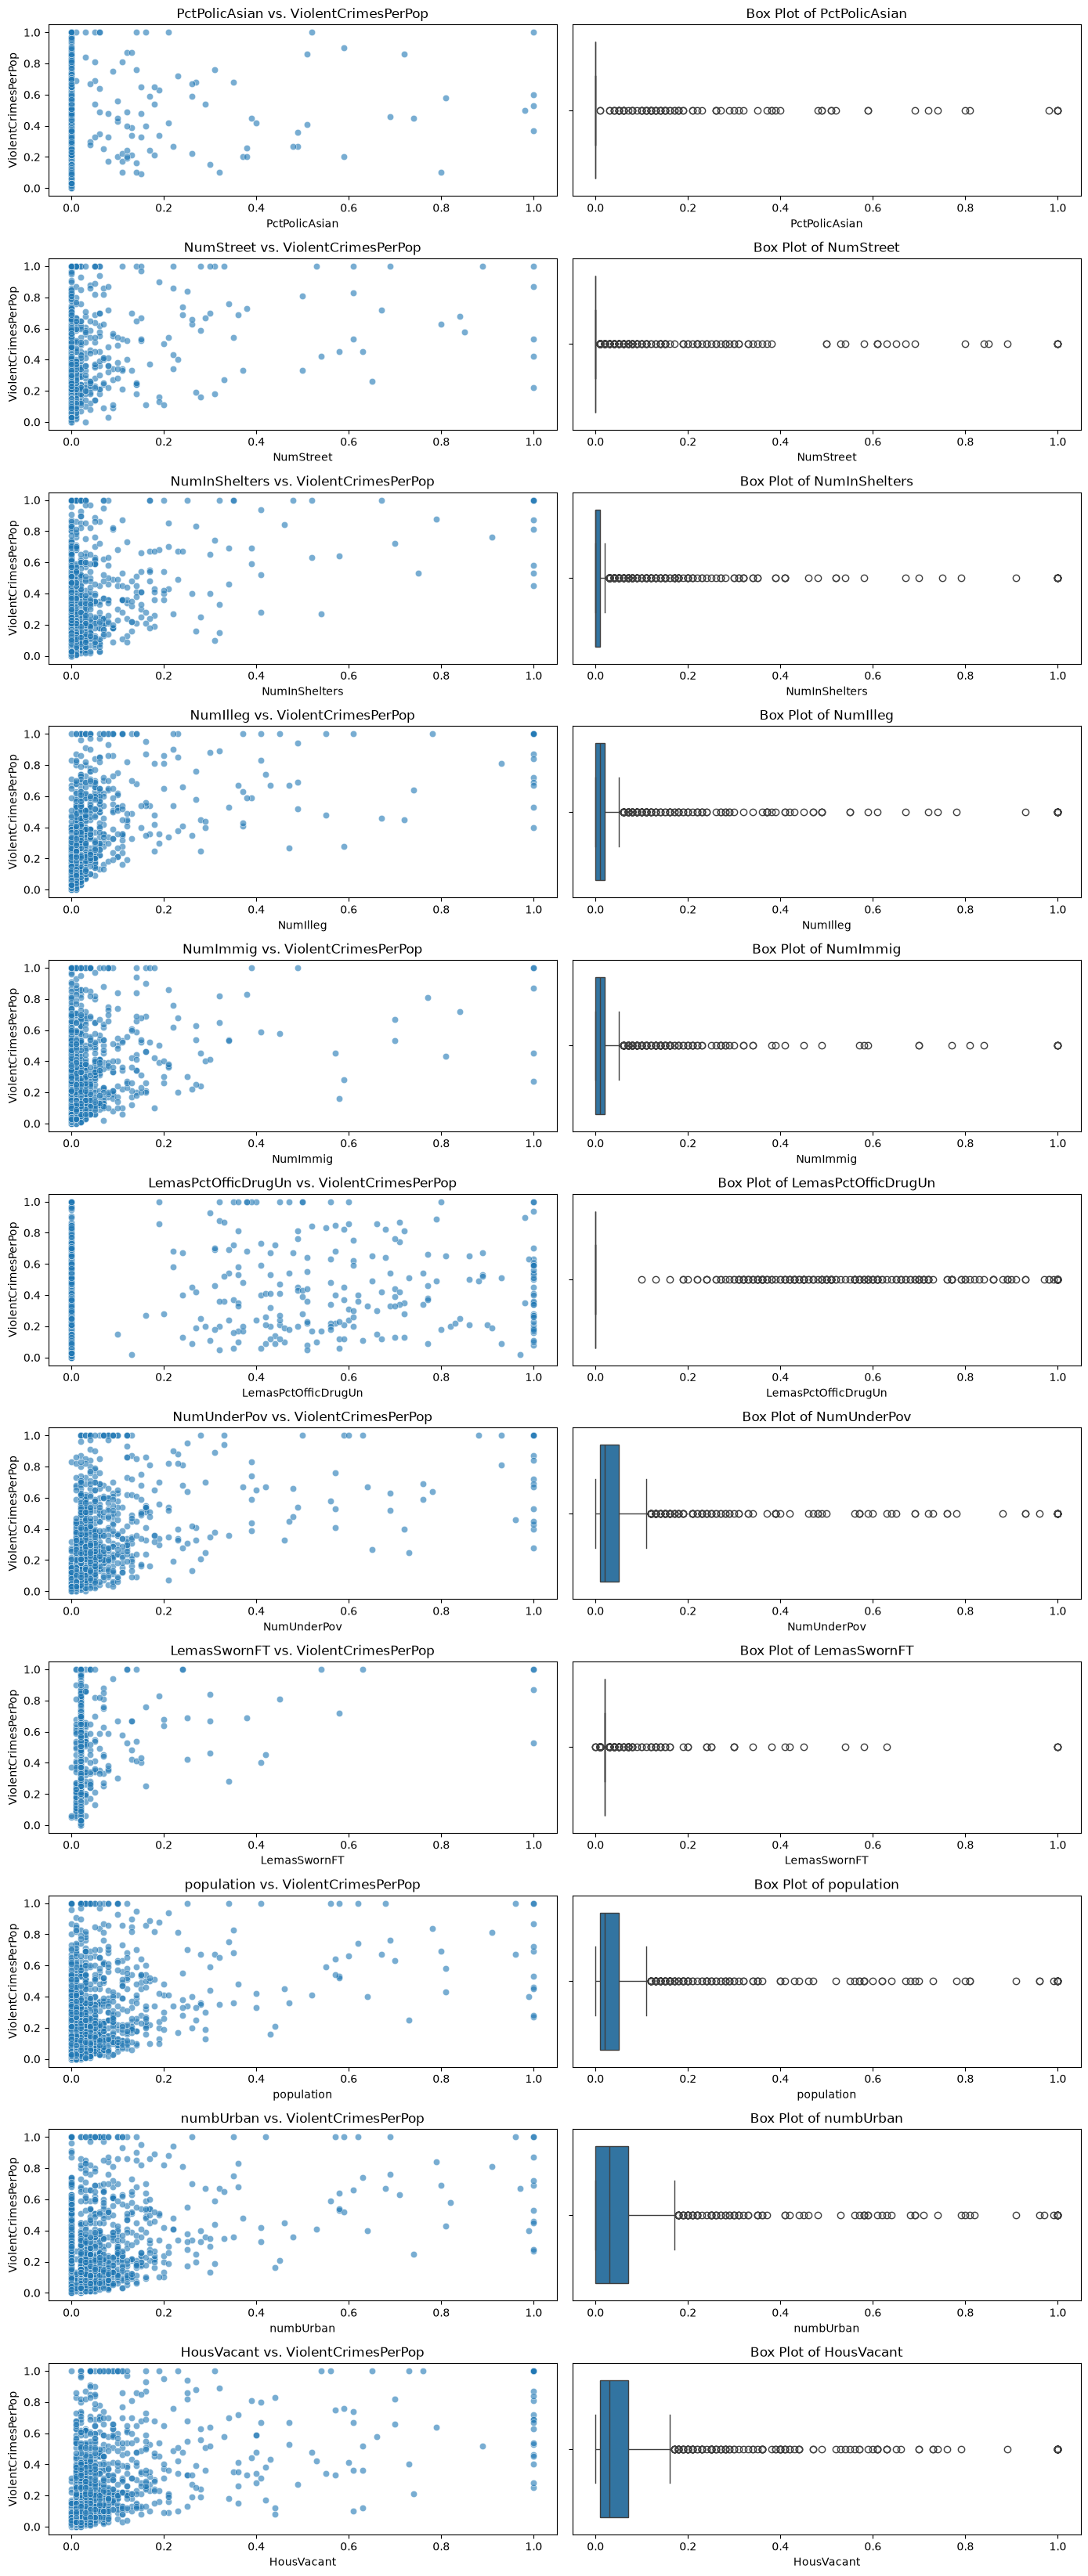

In [171]:
fig, axes = plt.subplots(
    nrows=number_of_features,
    ncols=2,
    figsize=(14, 3 * number_of_features)
)

for row, feature in enumerate(top_cv_features):
    sns.scatterplot(
        x=X_train_imputed[feature],
        y=y_train,
        ax=axes[row, 0],
        alpha=0.6
    )

    axes[row, 0].set_title(
        f"{feature} vs. ViolentCrimesPerPop"
    )
    axes[row, 0].set_xlabel(feature)
    axes[row, 0].set_ylabel(
        "ViolentCrimesPerPop"
    )

    sns.boxplot(
        x=X_train_imputed[feature],
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(
        f"Box Plot of {feature}"
    )
    axes[row, 1].set_xlabel(feature)

plt.tight_layout()
plt.show()

The scatter plots show possible relationships between the selected features and ViolentCrimesPerPop, while the box plots show their distributions and potential outliers. However, the significance of these features cannot be determined from the plots alone. A high coefficient of variation only indicates high variability relative to the mean and does not necessarily imply a strong relationship with the response. Formal statistical analysis or predictive validation is needed to determine feature significance.

### (f) Fit a linear model

In [173]:
from sklearn.model_selection import (KFold, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (LinearRegression, Ridge, Lasso)
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
regression_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [174]:
linear_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("linear", LinearRegression())])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
linear_test_mse = mean_squared_error(y_test, linear_predictions)
print("linear regression test MSE:", linear_test_mse)

linear regression test MSE: 0.01796621542606732


### (g) Fit a ridge regression model

In [175]:
ridge_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("ridge", Ridge())])
ridge_parameters = {"ridge__alpha": np.logspace(-4, 4, 100)}
ridge_search = GridSearchCV(ridge_model, param_grid=ridge_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
ridge_predictions = ridge_search.predict(X_test)
ridge_test_mse = mean_squared_error(y_test, ridge_predictions)
print("best ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("ridge CV MSE:", -ridge_search.best_score_)
print("ridge test MSE:", ridge_test_mse)

best ridge alpha: 138.48863713938746
ridge CV MSE: 0.019737002699083583
ridge test MSE: 0.01736038275948827


### (h) Fit a LASSO model

In [176]:
lasso_parameters = {"lasso__alpha": np.logspace(-5, 0, 100)}
lasso_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("lasso", Lasso(max_iter=100000))])
lasso_search = GridSearchCV(lasso_model, param_grid=lasso_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
lasso_predictions = lasso_search.predict(X_test)
lasso_test_mse = mean_squared_error(y_test, lasso_predictions)
print("best LASSO alpha:", lasso_search.best_params_["lasso__alpha"])
print("LASSO CV MSE:", -lasso_search.best_score_)
print("LASSO test MSE:", lasso_test_mse)

best LASSO alpha: 0.00011497569953977356
LASSO CV MSE: 0.019515040933210527
LASSO test MSE: 0.01763624099090411


In [177]:
lasso_coefficients = pd.Series(lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
lasso_selected = lasso_coefficients[lasso_coefficients.abs() > 1e-8].sort_values(key=np.abs, ascending=False)
print("number of selected variables:", len(lasso_selected))
lasso_selected.to_frame("coefficient")

number of selected variables: 74


,coefficient
racepctblack,0.268054
agePct12t29,-0.266204
PctPersDenseHous,0.215162
PctKids2Par,-0.198341
MedRent,0.161594
...,...
PctTeen2Par,-0.009588
PctImmigRec10,-0.004204
MedNumBR,0.003515
PctBornSameState,-0.000485


In [178]:
standardized_lasso_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("lasso", Lasso(max_iter=100000))])
standardized_lasso_search = GridSearchCV(standardized_lasso_model, param_grid=lasso_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
standardized_lasso_search.fit(X_train, y_train)
standardized_lasso_predictions = standardized_lasso_search.predict(X_test)
standardized_lasso_test_mse = mean_squared_error(y_test, standardized_lasso_predictions)
print("best standardized LASSO alpha:", standardized_lasso_search.best_params_["lasso__alpha"])
print("standardized LASSO CV MSE:", -standardized_lasso_search.best_score_)
print("standardized LASSO test MSE:", standardized_lasso_test_mse)

best standardized LASSO alpha: 0.0006579332246575682
standardized LASSO CV MSE: 0.019663110688751654
standardized LASSO test MSE: 0.01771423072023947


In [179]:
standardized_lasso_coeff = pd.Series(standardized_lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
standardized_lasso_selected = standardized_lasso_coeff[standardized_lasso_coeff.abs() > 1e-8].sort_values(key=np.abs, ascending=False)
print("number of selected variables:", len(standardized_lasso_selected))
standardized_lasso_selected.to_frame("coefficient")

number of selected variables: 75


,coefficient
racepctblack,0.067932
PctPersDenseHous,0.042706
agePct12t29,-0.042198
PctKids2Par,-0.040695
RentLowQ,-0.030151
...,...
PctImmigRec10,-0.000605
OwnOccLowQuart,-0.000602
PctOccupManu,0.000581
MedNumBR,0.000565


In [180]:
lasso_comparison = pd.DataFrame({"model": ["LASSO", "Standardized LASSO"], "best_alpha": [lasso_search.best_params_["lasso__alpha"], standardized_lasso_search.best_params_["lasso__alpha"]], "selected_variables": [len(lasso_selected), len(standardized_lasso_selected)], "test_MSE": [lasso_test_mse, standardized_lasso_test_mse]})
lasso_comparison

,model,best_alpha,selected_variables,test_MSE
0,LASSO,0.000115,74,0.017636
1,Standardized LASSO,0.000658,75,0.017714


### (i) Fit a PCR model

In [181]:
pcr_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("pca", PCA()), ("linear", LinearRegression())])
pcr_parameters = {"pca__n_components": np.arange(1, X_train.shape[1] + 1)}
pcr_search = GridSearchCV(pcr_model, param_grid=pcr_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)
pcr_predictions = pcr_search.predict(X_test)
pcr_test_mse = mean_squared_error(y_test, pcr_predictions)
print("best number of components:", pcr_search.best_params_["pca__n_components"])
print("PCR CV MSE:", -pcr_search.best_score_)
print("PCR test MSE:", pcr_test_mse)

best number of components: 60
PCR CV MSE: 0.02019904698611389
PCR test MSE: 0.01834952528616995


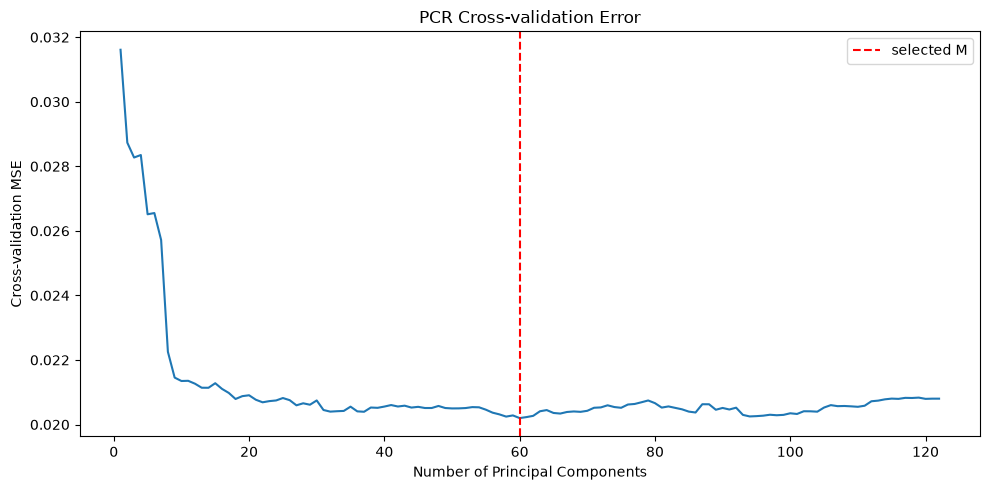

In [182]:
pcr_results = pd.DataFrame(pcr_search.cv_results_)
pcr_components = pcr_results["param_pca__n_components"].astype(int)
pcr_cv_mse = -pcr_results["mean_test_score"]
plt.figure(figsize=(10, 5))
plt.plot(pcr_components, pcr_cv_mse)
plt.axvline(pcr_search.best_params_["pca__n_components"], color="red", linestyle="--", label="selected M")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cross-validation MSE")
plt.title("PCR Cross-validation Error")
plt.legend()
plt.tight_layout()
plt.show()

### (j) Fit a boosting tree

In [184]:
from xgboost import XGBRegressor
xgboost_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("xgboost", XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=42, n_jobs=1))])
xgboost_parameters = {"xgboost__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
xgboost_search = GridSearchCV(xgboost_model, param_grid=xgboost_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
xgboost_search.fit(X_train, y_train)
xgboost_predictions = xgboost_search.predict(X_test)
xgboost_test_mse = mean_squared_error(y_test, xgboost_predictions)
print("best XGBoost alpha:", xgboost_search.best_params_["xgboost__reg_alpha"])
print("XGBoost CV MSE:", -xgboost_search.best_score_)
print("XGBoost test MSE:", xgboost_test_mse)

best XGBoost alpha: 1
XGBoost CV MSE: 0.019748660537689484
XGBoost test MSE: 0.0155300822929745


In [185]:
model_comparison = pd.DataFrame({"model": ["Linear Regression", "Ridge", "LASSO", "Standardized LASSO", "PCR", "XGBoost"], "test_MSE": [linear_test_mse, ridge_test_mse, lasso_test_mse, standardized_lasso_test_mse, pcr_test_mse, xgboost_test_mse]})
model_comparison = model_comparison.sort_values("test_MSE").reset_index(drop=True)
model_comparison

,model,test_MSE
0,XGBoost,0.015530
1,Ridge,0.017360
2,LASSO,0.017636
3,Standardized LASSO,0.017714
4,Linear Regression,0.017966
5,PCR,0.018350
